# Phase - 1 : ResNet50 Classification


In [ ]:
# Installing the libraries
!pip install torch torchvision

import torch
import torchvision

from torchvision import transforms
from torchvision import datasets
from torchvision import models

from torch import nn
from torch import optim

In [ ]:
# Generate a kaggle key and upload the json file here
from google.colab import files

files.upload()

Saving kaggle (1).json to kaggle (1) (1).json


{'kaggle (1) (1).json': b'{"username":"maulijain216","key":"898b3ba107353c8bc434273acd7e9248"}'}

In [ ]:
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

mkdir: cannot create directory ‘/root/.kaggle’: File exists
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [ ]:
# Unzip the dataset file
!kaggle datasets download -d sriramr/fruits-fresh-and-rotten-for-classification
!unzip -q fruits-fresh-and-rotten-for-classification.zip
!rm fruits-fresh-and-rotten-for-classification.zip

Dataset URL: https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification
License(s): unknown
100% 3.58G/3.58G [00:40<00:00, 95.2MB/s]

replace dataset/dataset/test/freshapples/Screen Shot 2018-06-08 at 4.59.44 PM.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace dataset/dataset/test/freshapples/Screen Shot 2018-06-08 at 5.01.15 PM.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: a
error:  invalid response [a]
replace dataset/dataset/test/freshapples/Screen Shot 2018-06-08 at 5.01.15 PM.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
y







In [ ]:
!ls

 apple.jpg	     fresh_oranges-in-a-box.jpg   rotten_mango.jpg
 banana.jpeg	    'kaggle (1) (1).json'	  rotten_orange3.jpg
 dataset	    'kaggle (1).json'		  rotten_orange.jpeg
 drive		     rotten_3pears.jpg		  rotten_pear.jpeg
 fresh_apple.jpeg    rotten_apple1.jpeg		  sample_data
 fresh_banana.jpeg   rotten_apple2.png		  strawberry.jpeg
 fresh_banana.jpg    rotten_apple.jpeg
 fresh_orange.jpg    rotten_banana.jpg


In [ ]:
!find . -type d

.
./.config
./.config/configurations
./.config/logs
./.config/logs/2026.06.04
./.ipynb_checkpoints
./dataset
./dataset/dataset
./dataset/dataset/train
./dataset/dataset/train/rottenbanana
./dataset/dataset/train/freshoranges
./dataset/dataset/train/rottenapples
./dataset/dataset/train/freshapples
./dataset/dataset/train/rottenoranges
./dataset/dataset/train/freshbanana
./dataset/dataset/test
./dataset/dataset/test/rottenbanana
./dataset/dataset/test/freshoranges
./dataset/dataset/test/rottenapples
./dataset/dataset/test/freshapples
./dataset/dataset/test/rottenoranges
./dataset/dataset/test/freshbanana
./dataset/train
./dataset/train/rottenbanana
./dataset/train/freshoranges
./dataset/train/rottenapples
./dataset/train/freshapples
./dataset/train/rottenoranges
./dataset/train/freshbanana
./dataset/test
./dataset/test/rottenbanana
./dataset/test/freshoranges
./dataset/test/rottenapples
./dataset/test/freshapples
./dataset/test/rottenoranges
./dataset/test/freshbanana
./drive
./drive/.sh

In [ ]:
# Configuration
# Dataset: Kaggle fruit freshness classification dataset
# Downloaded via Kaggle API in the cells above; lands at this path after unzip

DATASET_ROOT = "/content/dataset/dataset"
TRAIN_DIR = f"{DATASET_ROOT}/train"
VAL_DIR = f"{DATASET_ROOT}/test" # You can either use test set as validation or  split some images from test dataset and use it as validation. For example, in 7:2:1 ratio
TEST_DIR = f"{DATASET_ROOT}/test"

# Create a folder containing a handful of sample images for qualitative testing
SAMPLE_IMAGES_DIR = "/content/sample_images"

In [ ]:
# Transforming and augmentation of the dataset images

transform_train = transforms.Compose([
    transforms.RandomRotation(30),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

transform_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [ ]:
train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=transform_train # Use augmented transform for training
)

val_dataset = datasets.ImageFolder(
    VAL_DIR,
    transform=transform_val # Use standard transform for validation
)

# Create a mapping from class index to class name
idx_to_class = {v: k for k, v in train_dataset.class_to_idx.items()}

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32
)

In [ ]:
# Pre-trained (weights) ResNet50

model = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

In [ ]:
model.fc = nn.Linear(
    model.fc.in_features,
    6
)

In [ ]:
# Run it using T4-GPU (PREFERRED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model.to(device)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
criterion = nn.CrossEntropyLoss()

In [ ]:
optimizer = optim.Adam(
    model.parameters(),
    lr=51e-4
)

# NOTE : Approximate Training Time for this Model using T4-GPU : 50-60 minutes;
# [5-6 minutes per epoch]

In [ ]:
# Training Process!!

from tqdm.auto import tqdm
import numpy as np

epochs = 10

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for epoch in range(epochs):

    model.train()

    running_loss = 0
    correct_train = 0
    total_train = 0

    # Wrap train_loader with tqdm for a progress bar
    for images,labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} (Training)"):

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / len(train_loader)
    epoch_train_accuracy = 100 * correct_train / total_train
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_accuracy)

    print(
        f"Epoch {epoch+1} finished with training loss: "
        f"{epoch_train_loss:.4f}, training accuracy: {epoch_train_accuracy:.2f}%"
    )

    # Validation phase
    model.eval()
    running_val_loss = 0
    correct_val = 0
    total_val = 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} (Validation)"):
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    epoch_val_loss = running_val_loss / len(val_loader)
    epoch_val_accuracy = 100 * correct_val / total_val
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_accuracy)

    print(
        f"Epoch {epoch+1} finished with validation loss: "
        f"{epoch_val_loss:.4f}, validation accuracy: {epoch_val_accuracy:.2f}%"
    )


Epoch 1/10 (Training):   0%|          | 0/341 [00:00<?, ?it/s]

Epoch 1 finished with training loss: 1.0612, training accuracy: 58.89%


Epoch 1/10 (Validation):   0%|          | 0/85 [00:00<?, ?it/s]

Epoch 1 finished with validation loss: 0.9009, validation accuracy: 65.79%


Epoch 2/10 (Training):   0%|          | 0/341 [00:00<?, ?it/s]

Epoch 2 finished with training loss: 0.7991, training accuracy: 70.20%


... (30 outputs left out)

Epoch 10/10 (Training):   0%|          | 0/341 [00:00<?, ?it/s]

Epoch 10 finished with training loss: 0.2151, training accuracy: 92.63%


Epoch 10/10 (Validation):   0%|          | 0/85 [00:00<?, ?it/s]

Epoch 10 finished with validation loss: 0.2422, validation accuracy: 92.55%


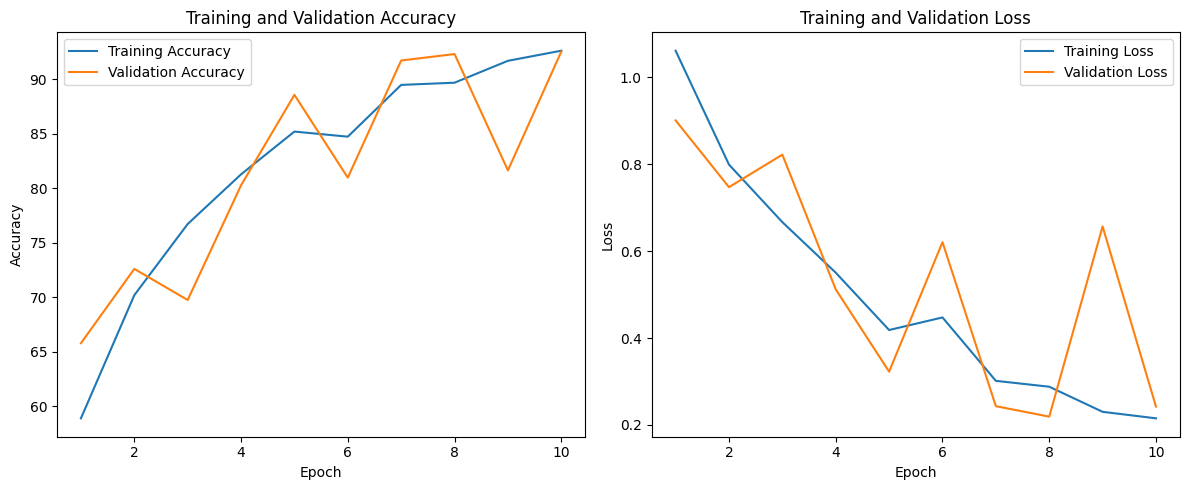

In [ ]:
# Accuracy and Loss Graphs !!

import matplotlib.pyplot as plt

epochs_range = range(1, epochs + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_accuracies, label='Training Accuracy')
plt.plot(epochs_range, val_accuracies, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_losses, label='Training Loss')
plt.plot(epochs_range, val_losses, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Save the model

torch.save(
    model.state_dict(),
    "fruit_classifier_phase1.pth"
)

### Testing with Multiple Images

Let's test the model with a few different images to see its predictions and confidence scores.

In [ ]:
# Testing with some sample images!!

from PIL import Image
import torch.nn.functional as F

sample_filenames = [] # Add as many sample images you want to check : make sure the paths are within double quotations and for more than one image, separate the paths using commas.

test_image_paths = [f"{SAMPLE_IMAGES_DIR}/{f}" for f in sample_filenames
                    ]
model.eval() # Ensure the model is in evaluation mode

for img_path in test_image_paths:
    print(f"\nProcessing image: {img_path.split('/')[-1]}")
    try:
        image = Image.open(img_path)
        if image.mode == 'RGBA':
            image = image.convert('RGB')
        img = transform_val(image).unsqueeze(0).to(device) # Changed from transform to transform_val

        with torch.no_grad():
            output = model(img)

        prediction = output.argmax(1)
        pred_class = idx_to_class[prediction.item()]

        probs = F.softmax(output, dim=1)
        confidence = probs.max().item()

        print(f"Prediction: {pred_class}")
        print(f"Confidence: {confidence*100:.2f}%")
    except FileNotFoundError:
        print(f"Error: Image not found at {img_path}")
    except Exception as e:
        print(f"An error occurred while processing {img_path}: {e}")


Processing image: rotten_banana.jpg
Prediction: rottenbanana
Confidence: 100.00%

Processing image: fresh_apple.jpeg
Prediction: freshbanana
Confidence: 89.77%

Processing image: fresh_banana.jpeg
Prediction: freshbanana
Confidence: 100.00%

Processing image: fresh_orange.jpg
Prediction: freshoranges
Confidence: 95.55%

Processing image: rotten_apple.jpeg
Prediction: rottenapples
Confidence: 53.28%

Processing image: rotten_apple1.jpeg
Prediction: rottenapples
Confidence: 97.91%

Processing image: rotten_apple2.png
Prediction: rottenapples
Confidence: 99.37%

Processing image: rotten_banana.jpg
Prediction: rottenbanana
Confidence: 100.00%

Processing image: rotten_orange.jpeg
Prediction: freshbanana
Confidence: 69.04%

Processing image: rotten_orange3.jpg
Prediction: rottenbanana
Confidence: 96.12%


### Model Accuracy on Test Dataset

Now, let's evaluate the model's performance on the full test dataset to get an overall accuracy score.

In [ ]:
test_dataset_path = TEST_DIR # Enter the test dataset path here

# Create a new DataLoader for the test dataset

test_dataset = datasets.ImageFolder(
    test_dataset_path,
    transform=transform_val  # Use the validation transform for the test set
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

correct = 0
total = 0
model.eval() # Set the model to evaluation mode

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f'Accuracy of the model on the {total} test images: {accuracy:.2f}%')

Accuracy of the model on the 2698 test images: 92.55%


### Model Evaluation: Inference Time, Precision, and Recall

Dice Score and IoU are primarily used for image segmentation tasks to measure the overlap between predicted and ground truth masks. Since this model performs image classification (predicting categories like 'freshapples' or 'rottenbanana'), these metrics are not directly applicable. Instead, we will focus on metrics relevant to classification, such as Precision, Recall, F1-score, and also measure the inference speed (FPS).

In [ ]:
import time
from sklearn.metrics import classification_report

# Calculate Inference Time (FPS)

model.eval() # Ensure the model is in evaluation mode

start_time = time.time()
num_batches = 0
total_images_processed = 0

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)
        _ = model(images)
        num_batches += 1
        total_images_processed += images.size(0)

end_time = time.time()
time_taken = end_time - start_time

if num_batches > 0:
    # Calculate FPS
    fps = total_images_processed / time_taken
    print(f"\nInference Time for {total_images_processed} images in {num_batches} batches: {time_taken:.4f} seconds")
    print(f"Average FPS: {fps:.2f} frames per second")
else:
    print("No batches processed for FPS calculation. Test loader might be empty.")


Inference Time for 2698 images in 85 batches: 16.6073 seconds
Average FPS: 162.46 frames per second


In [ ]:
# Calculate Precision, Recall, and F1-score

all_labels = []
all_predictions = []

model.eval() # Set the model to evaluation mode

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

# Generate a classification report
# Using idx_to_class to get class names for the report
class_names = [idx_to_class[i] for i in sorted(idx_to_class.keys())]

print("\nClassification Report:")
print(classification_report(all_labels, all_predictions, target_names=class_names))


Classification Report:
               precision    recall  f1-score   support

  freshapples       0.98      0.80      0.88       395
  freshbanana       0.98      0.92      0.95       381
 freshoranges       0.93      0.90      0.91       388
 rottenapples       0.83      0.96      0.89       601
 rottenbanana       0.98      0.99      0.99       530
rottenoranges       0.92      0.94      0.93       403

     accuracy                           0.93      2698
    macro avg       0.94      0.92      0.92      2698
 weighted avg       0.93      0.93      0.93      2698



In [ ]:
from sklearn.metrics import classification_report

# Generate the classification report as a dictionary
report = classification_report(all_labels, all_predictions, target_names=class_names, output_dict=True)

weighted_avg_recall = report['weighted avg']['recall']
print(f"Weighted Average Recall for the entire model: {weighted_avg_recall:.2f}")

Weighted Average Recall for the entire model: 0.93


In [ ]:
from sklearn.metrics import classification_report

# Generate the classification report as a dictionary
report = classification_report(all_labels, all_predictions, target_names=class_names, output_dict=True)

print("Recall for each class:")
for class_name in class_names:
    if class_name in report:
        print(f"  {class_name}: {report[class_name]['recall']:.2f}")

Recall for each class:
  freshapples: 0.80
  freshbanana: 0.92
  freshoranges: 0.90
  rottenapples: 0.96
  rottenbanana: 0.99
  rottenoranges: 0.94


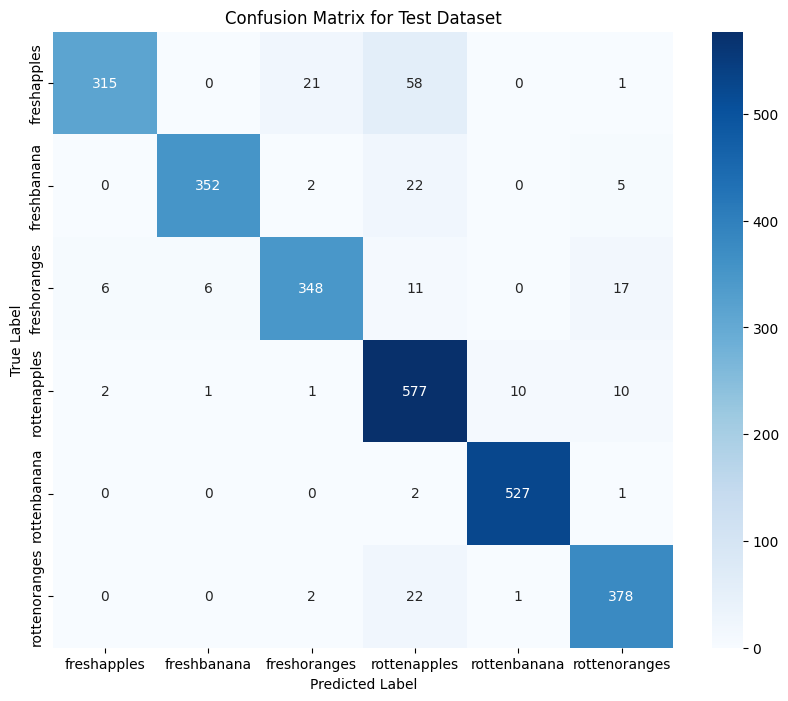

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Compute the confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

# Get class names for better readability
class_names = [idx_to_class[i] for i in sorted(idx_to_class.keys())]

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Test Dataset')
plt.show()

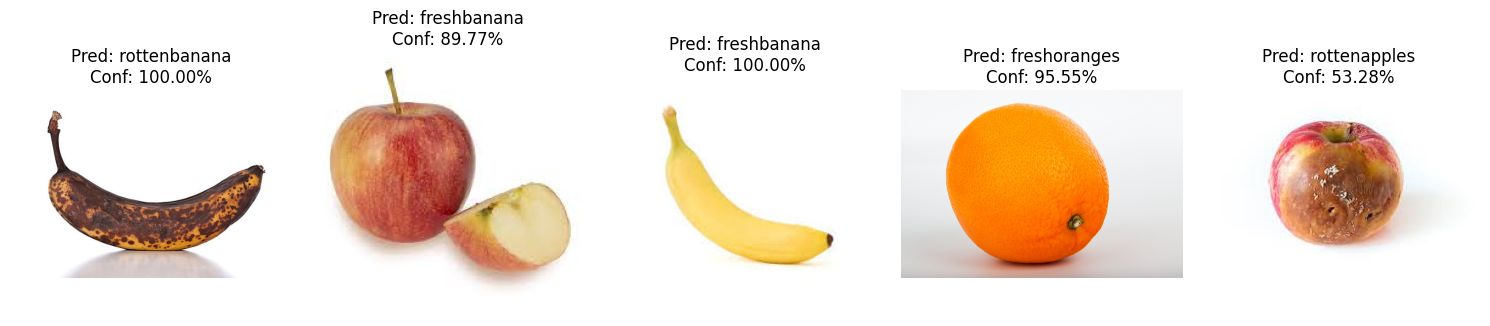

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Select a subset of images to display (e.g., the first 5 or a random selection)
sample_image_paths = test_image_paths[:5] # Taking the first 5 images for demonstration

plt.figure(figsize=(15, 8))

model.eval() # Ensure the model is in evaluation mode

for i, img_path in enumerate(sample_image_paths):
    try:
        image = Image.open(img_path)
        if image.mode == 'RGBA':
            image = image.convert('RGB')

        # Prepare image for model input
        img_tensor = transform_val(image).unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(img_tensor)

        prediction = output.argmax(1)
        pred_class = idx_to_class[prediction.item()]

        probs = F.softmax(output, dim=1)
        confidence = probs.max().item()

        # Plotting
        plt.subplot(1, len(sample_image_paths), i + 1)
        plt.imshow(image) # Display original image
        plt.title(f"Pred: {pred_class}\nConf: {confidence*100:.2f}%")
        plt.axis('off')

    except FileNotFoundError:
        print(f"Warning: Image not found at {img_path}. Skipping.")
        continue
    except Exception as e:
        print(f"An error occurred while processing {img_path}: {e}. Skipping.")
        continue

plt.tight_layout()
plt.show()

In [ ]:
# PHASE 1 IS COMPLETED !!